# Optimización de turnos y cobertura: controles y escenarios

Consulta la [metodología](../docs/metodologia.md) y ejecuta las etapas en orden. Los comentarios se calculan con los resultados guardados.

In [1]:
from pathlib import Path
import sys
here = Path.cwd().resolve()
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("workforce_scheduling")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre este notebook desde su proyecto independiente.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from workforce_scheduling.alerts import configurar_notebook, mostrar_alertas
from IPython.display import display, Markdown, Image
configurar_notebook()


# Optimización de turnos y cobertura: evaluacion

El plan optimizado supera cobertura y restricciones estructurales en las **140 franjas**. El baseline no cubre toda la demanda; su menor coste, si lo hubiera, no demuestra ahorro comparable. Al mantener los turnos y aumentar los requisitos un 20 % (redondeo al entero superior), **69 franjas** quedan cortas, con **87 agente-intervalos** de déficit. El escenario de estrés no se reoptimiza ni es una garantía probabilística. Son reglas didácticas, no un calendario de una empresa, cumplimiento de legislación laboral ni SLA. No se modelan habilidades, vacaciones ni rotación entre semanas.

## Equilibrio y preferencias

Ambos planes cubren la demanda. El escenario alternativo reduce o intercambia rango de horas y preferencias bajo un tope de coste: rango **40 → 8 horas**, preferencias incumplidas **39 → 18**, coste **6,409.60 unidades** (**+8.56%** respecto al plan de coste mínimo). La función objetivo pondera rango de horas y turnos fuera del inicio preferido; su gap corresponde a esa puntuación, no a minimizar coste. Preferencias y reglas son sintéticas; equilibrar horas es una medida específica y no certifica equidad laboral.

El solver alternativo **alcanzó el límite de tiempo con una solución factible; no se certifica optimalidad**; gap de su objetivo **22.00%**.



,Indicador,Valor
0,gap_relativo,0.000000
1,escenario_mas20pct_deficit_agente_intervalos,87.000000
2,escenario_mas20pct_intervalos_sin_cobertura,69.000000
3,ahorro_frente_baseline_factible,NaN
4,incremento_coste_relativo,0.085637
5,tope_incremento_relativo,0.100000
6,equilibrio_solver_status,1.000000
7,equilibrio_gap_objetivo,0.220000


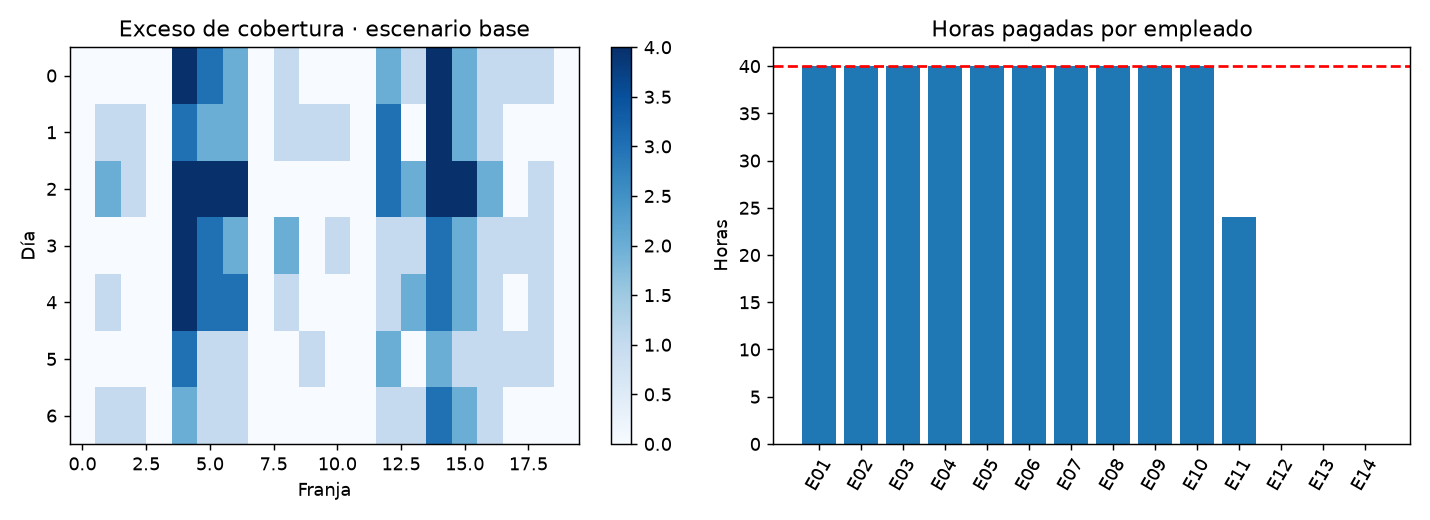

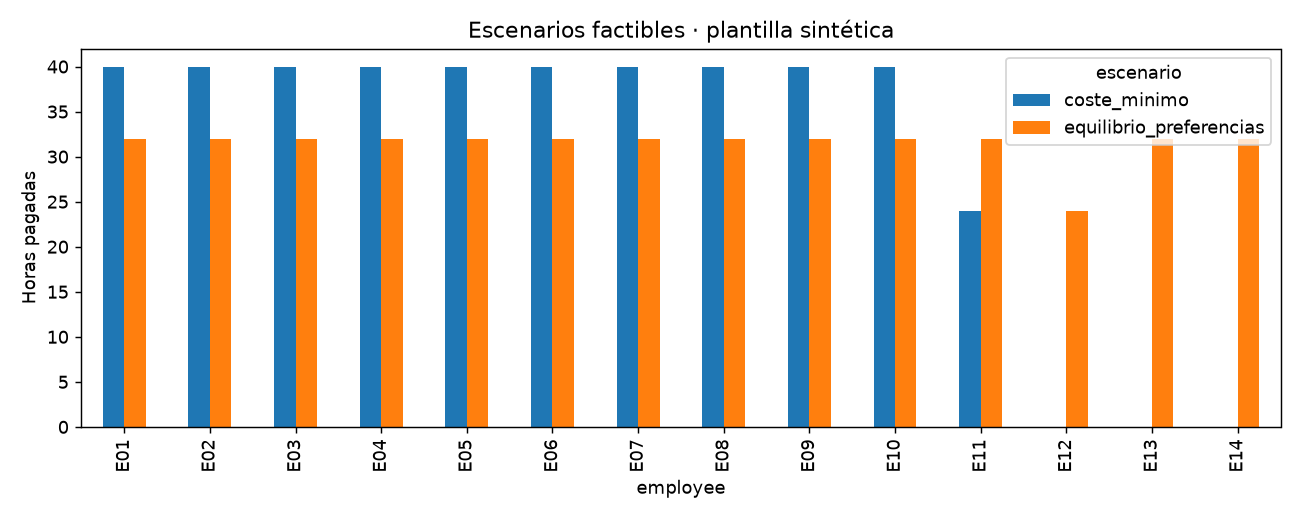

,employee,horas_pagadas,dias_trabajados,coste_unidades
0,E01,40,5,480.0
1,E02,40,5,496.0
2,E03,40,5,512.0
3,E04,40,5,528.0
4,E05,40,5,544.0
5,E06,40,5,560.0
6,E07,40,5,576.0
7,E08,40,5,592.0
8,E09,40,5,608.0
9,E10,40,5,624.0


In [2]:
from workforce_scheduling.analysis import run_stage
import pandas as pd
metrics,comment=run_stage(PROJECT_ROOT,"evaluacion")
display(Markdown(comment))
scalars={k:v for k,v in metrics.items() if not isinstance(v,(dict,list))}
if scalars:display(pd.DataFrame(list(scalars.items()),columns=["Indicador","Valor"]))
if "candidatos" in metrics:display(pd.DataFrame(metrics["candidatos"]))
for filename in ["eda.png","evaluacion.png","equilibrio.png"]:
    path=PROJECT_ROOT/"reports/evaluacion"/filename
    if path.exists():display(Image(filename=str(path)))
for filename in ["estimaciones.csv","metricas_test.csv","horas_por_empleado.csv"]:
    path=PROJECT_ROOT/"reports/evaluacion"/filename
    if path.exists():display(pd.read_csv(path).head(20))

In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from workforce_scheduling.informe import generar_informe
generar_informe(PROJECT_ROOT)
display(Markdown("[Abrir informe integral](../reports/informe_final/informe_final.md)"))

[Abrir informe integral](../reports/informe_final/informe_final.md)